# Phase 4 — Feature Engineering and Leakage-Safe Feature Pipeline

This notebook converts the approved Phase 3 ideas into deterministic, reusable predictor transformations. It does not train or evaluate a classification model. The goal is to enrich the predictor representation while keeping every learned preprocessing operation inside a future cross-validation pipeline.

## 1. Scope and safeguards

The existing Phase 2 cleaned file and fingerprint-bound split are mandatory. Feature selection and all descriptive checks use only the 960 training rows. `customer_id` and `churn` are removed before feature engineering. The 240 final-test rows are not constructed, summarized, or scored. No target values define a formula, threshold, encoding, or aggregate.

In [1]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

CURRENT = Path.cwd().resolve()
ROOT = CURRENT.parent if CURRENT.name == 'notebooks' else CURRENT
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.feature_engineering import (
    ENGINEERED_NUMERICAL_FEATURES,
    CustomerFeatureEngineer,
    build_feature_preprocessing_pipeline,
)
from src.preprocessing import (
    CATEGORICAL_FEATURES,
    IDENTIFIER_COLUMN,
    NUMERICAL_FEATURES,
    TARGET_COLUMN,
    create_or_load_fixed_split,
    load_and_validate_data,
    separate_features_target_ids,
)

CLEANED_PATH = ROOT / 'data' / 'processed' / '02_cleaned_dataset.csv'
SPLIT_PATH = ROOT / 'data' / 'processed' / '02_split_indices.json'
FIGURE_DIR = ROOT / 'reports' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

BLUE = '#3569D4'
PURPLE = '#8051D6'
LIGHT_PURPLE = '#B9A2EA'
sns.set_theme(style='whitegrid', context='talk')
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

def save_figure(fig, filename):
    fig.tight_layout()
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved: {path.relative_to(ROOT)}')

## 2. Load the exact Phase 2 training partition

Execution stops if either artifact is missing or if the saved split does not match the cleaned dataset. Reading the split indices is necessary to select the approved training rows; no held-out dataframe is created.

In [2]:
if not CLEANED_PATH.is_file():
    raise FileNotFoundError(f'Required Phase 2 cleaned dataset is missing: {CLEANED_PATH}')
if not SPLIT_PATH.is_file():
    raise FileNotFoundError(f'Required Phase 2 split artifact is missing: {SPLIT_PATH}')

cleaned_hash_before = hashlib.sha256(CLEANED_PATH.read_bytes()).hexdigest()
split_hash_before = hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest()
cleaned_df = load_and_validate_data(CLEANED_PATH)
split = create_or_load_fixed_split(
    cleaned_df, SPLIT_PATH, test_size=0.20, random_state=42
)
if not split['loaded_existing']:
    raise RuntimeError('Phase 4 requires the previously saved Phase 2 split.')

train_indices = split['train_indices']
test_indices = split['test_indices']
train_df = cleaned_df.iloc[train_indices].copy()
X_train, _, _ = separate_features_target_ids(train_df)

assert set(train_indices).isdisjoint(test_indices)
print(f'Training rows used: {len(X_train):,}')
print(f'Final-test rows kept sealed: {len(test_indices):,}')
print(f'Split fingerprint: {split["dataset_fingerprint"]}')
print(f'Original predictor count: {X_train.shape[1]}')

Training rows used: 960
Final-test rows kept sealed: 240
Split fingerprint: df788deba598b73abdc3a41b8a1947af63a90c5f369c2a498386a2c0eefeb769
Original predictor count: 18


## 3. EDA findings used

Phase 3 found that usage had the clearest descriptive separation, month-to-month contracts had higher churn across tenure groups, satisfaction interacted with complaints, and repeated late payments showed a possible threshold pattern. Tenure and charges were not simply linear. These findings motivate interactions and ratios, but they do not prove causality or future model improvement.

Temporal definitions remain incomplete. In particular, usage, complaints, satisfaction, and payment-history windows must end before the prediction date. Derived features inherit any timing risk in their source fields.

## 4. Original feature overview

In [3]:
feature_overview = pd.DataFrame({
    'feature': X_train.columns,
    'role': [
        'numerical' if column in NUMERICAL_FEATURES else 'categorical'
        for column in X_train.columns
    ],
    'dtype': X_train.dtypes.astype(str).values,
    'missing': X_train.isna().sum().values,
})
display(feature_overview)
print(f'Numerical predictors: {len(NUMERICAL_FEATURES)}')
print(f'Categorical predictors: {len(CATEGORICAL_FEATURES)}')

,feature,role,dtype,missing
0,age,numerical,int64,0
1,tenure_months,numerical,int64,0
2,monthly_charges,numerical,float64,28
3,total_charges,numerical,float64,20
4,complaints_last_12m,numerical,int64,0
5,late_payments_last_12m,numerical,int64,0
6,satisfaction_score,numerical,float64,38
7,monthly_usage_gb,numerical,float64,23
8,discount_pct,numerical,float64,0
9,contract_type,categorical,str,0


Numerical predictors: 9
Categorical predictors: 9


## 5. Accepted engineered features

| Feature | Source columns | Formula | Business rationale | Missing behavior | Leakage assessment and limitation |
|---|---|---|---|---|---|
| `tenure_years` | `tenure_months` | tenure ÷ 12 | Human-readable relationship duration | Missing tenure stays missing | No target use; exactly redundant with tenure months |
| `complaints_per_active_month` | complaints, tenure | complaints ÷ min(max(tenure, 1), 12) | Approximate complaint intensity over observed exposure | Missing source stays missing; zero tenure uses a one-month floor | The complaint window is documented only as “last 12 months,” so this is an approximation |
| `payment_risk_score` | complaints, late payments | complaints + late payments | Simple combined service/payment-friction count | Missing source yields missing | Equal-weight heuristic, not a validated financial risk score |
| `complaint_satisfaction_interaction` | complaints, satisfaction | complaints × (10 − satisfaction) | Combine complaints with lower satisfaction | Missing source yields missing | Uses the Phase 2 validated 0–10 scale; timestamp availability remains unconfirmed |
| `monthly_contract_tenure` | tenure, contract type | tenure × I(month-to-month) | Represent the EDA contract-by-tenure pattern | Missing tenure or contract yields missing | Exact category label verified; no target encoding |
| `late_payment_charge_interaction` | late payments, monthly charges | late payments × monthly charges | Represent simultaneous payment delays and higher current charges | Missing source yields missing | Interaction score only—not an overdue monetary balance |
| `usage_per_charge` | usage, monthly charges | usage ÷ monthly charges | Express usage intensity relative to current charge | Missing/non-positive denominator yields missing | Not monetary ROI; usage timing and service scope require confirmation |

### Deferred candidate

`charges_per_tenure = total_charges / tenure_months` is not implemented. Audits found unexplained discrepancies between current monthly charges, cumulative charges, discounts, and tenure. The cumulative-charge definition and prediction-time availability require business confirmation first. Target-derived tenure bands and usage thresholds are also not implemented; any data-driven thresholds would need to be learned inside training folds.

## 6. Deterministic implementation and numerical examples

The scikit-learn-compatible transformer copies its input, validates required sources, appends stable numerical columns, and learns no values during `fit`.

In [4]:
feature_engineer = CustomerFeatureEngineer()
engineered_train = feature_engineer.fit_transform(X_train)

assert engineered_train.index.equals(X_train.index)
assert len(engineered_train) == len(X_train)
assert list(feature_engineer.get_feature_names_out()) == list(engineered_train.columns)
assert IDENTIFIER_COLUMN not in engineered_train.columns
assert TARGET_COLUMN not in engineered_train.columns

print(f'Before feature engineering: {X_train.shape[1]} predictors')
print(f'After feature engineering: {engineered_train.shape[1]} predictors')
print(f'New features: {list(ENGINEERED_NUMERICAL_FEATURES)}')

Before feature engineering: 18 predictors
After feature engineering: 25 predictors
New features: ['tenure_years', 'complaints_per_active_month', 'payment_risk_score', 'complaint_satisfaction_interaction', 'monthly_contract_tenure', 'late_payment_charge_interaction', 'usage_per_charge']


In [5]:
example_columns = [
    'tenure_months', 'complaints_last_12m', 'late_payments_last_12m',
    'satisfaction_score', 'contract_type', 'monthly_charges',
    'monthly_usage_gb', *ENGINEERED_NUMERICAL_FEATURES,
]
display(engineered_train.loc[:, example_columns].head(6))

,tenure_months,complaints_last_12m,late_payments_last_12m,satisfaction_score,contract_type,monthly_charges,monthly_usage_gb,tenure_years,complaints_per_active_month,payment_risk_score,complaint_satisfaction_interaction,monthly_contract_tenure,late_payment_charge_interaction,usage_per_charge
492,48,0,2,5.3000,One year,81.3200,73.0000,4.0000,0.0000,2.0000,0.0000,0.0000,162.6400,0.8977
398,61,2,2,4.6000,Two year,52.4000,58.0000,5.0833,0.1667,4.0000,10.8000,0.0000,104.8000,1.1069
79,63,1,0,7.3000,Month-to-month,59.2600,106.6000,5.2500,0.0833,1.0000,2.7000,63.0000,0.0000,1.7989
614,64,1,1,8.2000,Month-to-month,45.0900,37.2000,5.3333,0.0833,2.0000,1.8000,64.0000,45.0900,0.8250
527,42,0,0,5.2000,Month-to-month,34.2600,63.7000,3.5000,0.0000,0.0000,0.0000,42.0000,0.0000,1.8593
698,54,1,0,5.0000,Month-to-month,105.9000,52.4000,4.5000,0.0833,1.0000,5.0000,54.0000,0.0000,0.4948


The examples intentionally omit customer identifiers. Values can be recalculated directly from the displayed source columns; for example, a 24-month tenure becomes 2 years, and the month-to-month interaction is zero for known fixed-term contracts.

## 7. Descriptive statistics and safety checks

In [6]:
engineered_only = engineered_train.loc[:, ENGINEERED_NUMERICAL_FEATURES]
display(engineered_only.describe().T)
missing_summary = engineered_only.isna().sum().rename('missing_count').to_frame()
missing_summary['missing_pct'] = missing_summary['missing_count'] / len(engineered_only) * 100
display(missing_summary)

infinite_count = int(np.isinf(engineered_only.to_numpy(dtype='float64')).sum())
print(f'Infinite engineered values: {infinite_count}')
print(f'Rows preserved: {len(engineered_train) == len(X_train)}')

,count,mean,std,min,25%,50%,75%,max
tenure_years,960.0000,2.9884,1.7612,0.0833,1.5000,2.9167,4.5000,6.0000
complaints_per_active_month,960.0000,0.0782,0.1548,0.0000,0.0000,0.0833,0.0833,2.0000
payment_risk_score,960.0000,1.5240,1.2612,0.0000,1.0000,1.0000,2.0000,8.0000
complaint_satisfaction_interaction,922.0000,2.2439,3.3115,0.0000,0.0000,0.0000,3.7000,23.7000
monthly_contract_tenure,960.0000,21.5281,24.3151,0.0000,0.0000,11.0000,42.2500,72.0000
late_payment_charge_interaction,932.0000,59.2099,70.5576,0.0000,0.0000,48.6150,88.7950,451.7600
usage_per_charge,910.0000,1.0785,0.8532,0.0166,0.5723,0.9423,1.3528,7.7568


,missing_count,missing_pct
tenure_years,0,0.0000
complaints_per_active_month,0,0.0000
payment_risk_score,0,0.0000
complaint_satisfaction_interaction,38,3.9583
monthly_contract_tenure,0,0.0000
late_payment_charge_interaction,28,2.9167
usage_per_charge,50,5.2083


Infinite engineered values: 0
Rows preserved: True


Missingness is propagated rather than filled by feature engineering. The downstream numerical imputer will learn replacement values from each training fold. `usage_per_charge` has more missing values than either source alone because it requires both usage and charge values.

## 8. Engineered-feature distributions

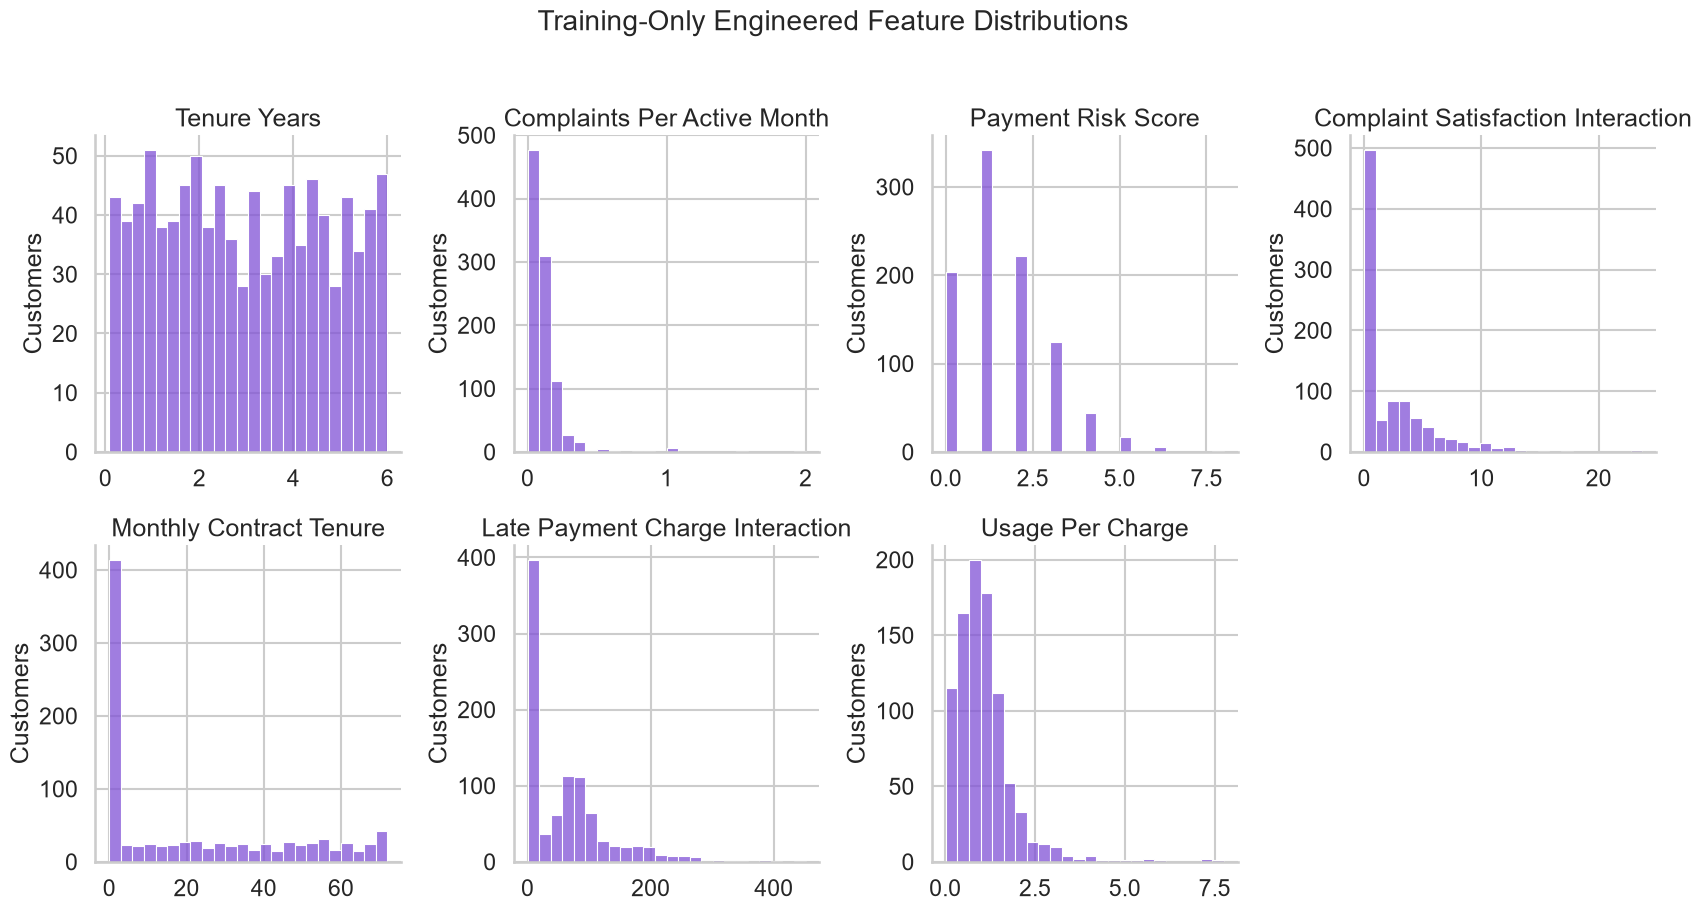

Saved: reports\figures\fe_01_engineered_feature_distributions.png


In [7]:
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for ax, column in zip(axes.flat, ENGINEERED_NUMERICAL_FEATURES):
    sns.histplot(engineered_only[column], bins=24, color=PURPLE, ax=ax)
    ax.set(title=column.replace('_', ' ').title(), xlabel='', ylabel='Customers')
axes.flat[-1].axis('off')
fig.suptitle('Training-Only Engineered Feature Distributions', fontsize=20, y=1.02)
sns.despine(fig=fig)
save_figure(fig, 'fe_01_engineered_feature_distributions.png')

### Interpretation

Several engineered fields are right-skewed or contain a large zero mass, reflecting the many customers with no complaints, late payments, or month-to-month interaction. `payment_risk_score` ranges from 0 to 8, while the complaint-satisfaction interaction reaches 23.7. These distributions justify keeping imputation and scaling inside the model pipeline rather than altering persisted data. Extreme values remain because no source evidence identifies them as errors.

## 9. Before-and-after relationships

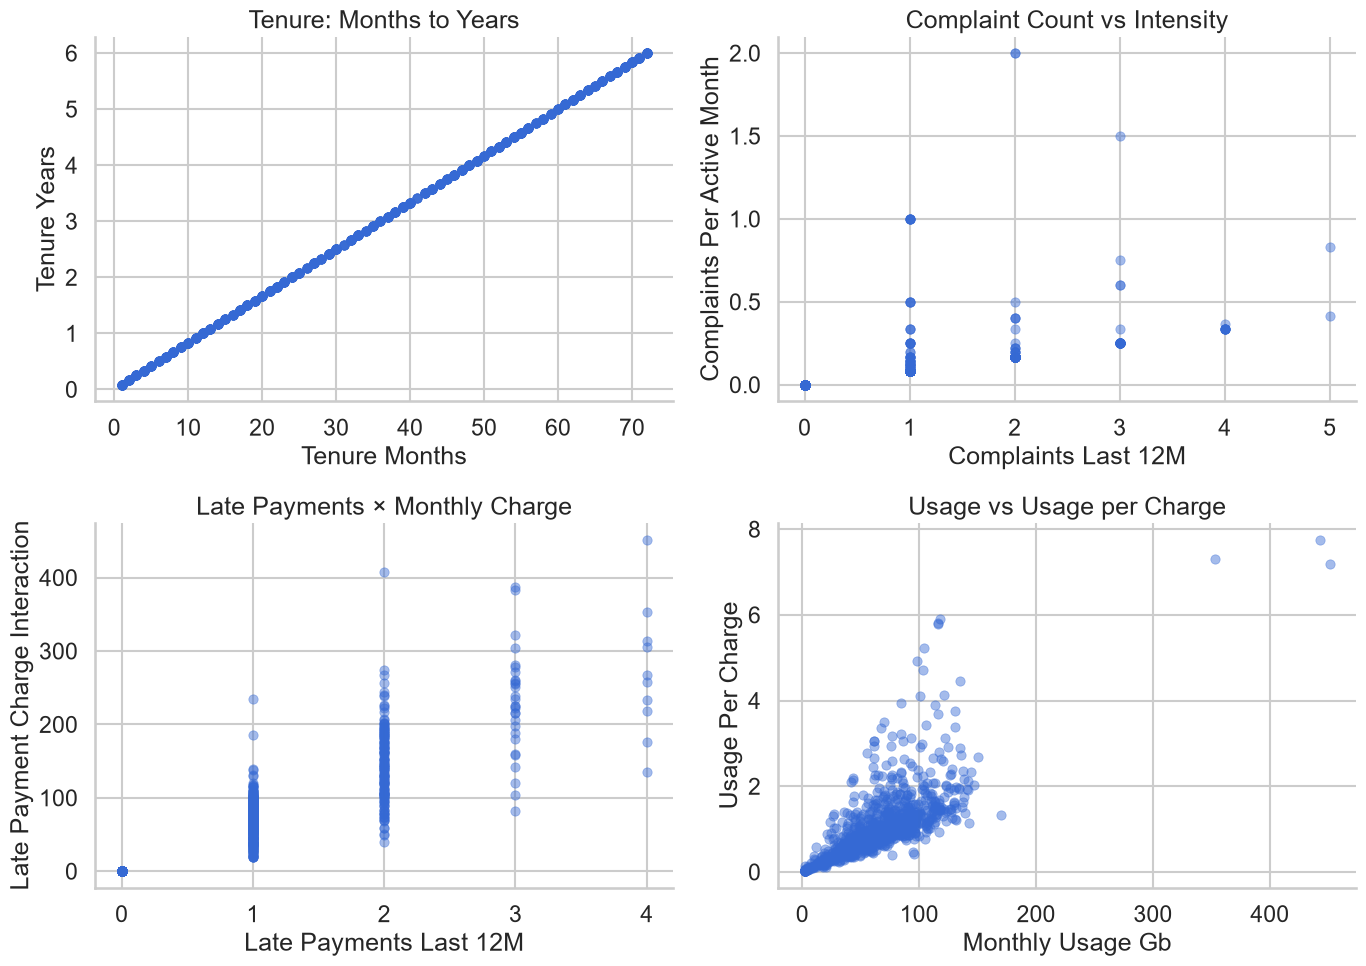

Saved: reports\figures\fe_02_source_engineered_relationships.png


In [8]:
comparison_pairs = [
    ('tenure_months', 'tenure_years', 'Tenure: Months to Years'),
    ('complaints_last_12m', 'complaints_per_active_month', 'Complaint Count vs Intensity'),
    ('late_payments_last_12m', 'late_payment_charge_interaction', 'Late Payments × Monthly Charge'),
    ('monthly_usage_gb', 'usage_per_charge', 'Usage vs Usage per Charge'),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (source, engineered, title) in zip(axes.flat, comparison_pairs):
    sns.scatterplot(
        data=engineered_train, x=source, y=engineered,
        color=BLUE, alpha=0.45, s=45, edgecolor=None, ax=ax,
    )
    ax.set(title=title, xlabel=source.replace('_', ' ').title(), ylabel=engineered.replace('_', ' ').title())
sns.despine(fig=fig)
save_figure(fig, 'fe_02_source_engineered_relationships.png')

### Interpretation

`tenure_years` is an exact rescaling and therefore adds interpretability rather than information. Other transformations change the geometry: complaint intensity is larger for complaints during short tenure, the payment-charge interaction spreads repeated-payment cases according to current charge, and usage per charge can be high even at moderate usage when monthly charges are low. These patterns may help some model families, but usefulness must be tested in Phase 5.

## 10. Redundancy and correlation review

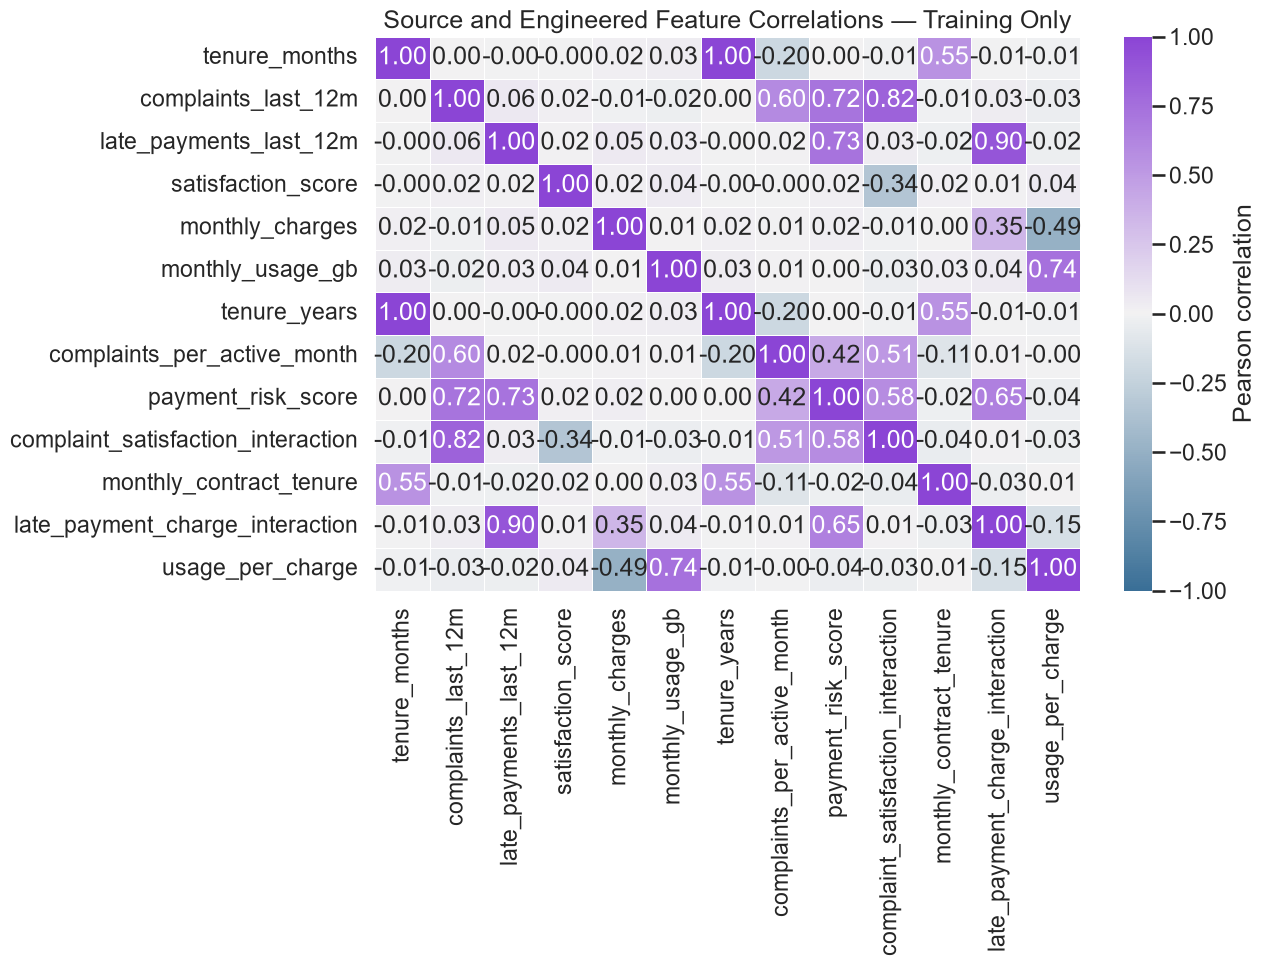

Saved: reports\figures\fe_03_feature_correlation_heatmap.png


,,absolute_correlation
tenure_months,tenure_years,1.0000
late_payments_last_12m,late_payment_charge_interaction,0.9019
tenure_months,total_charges,0.8321
total_charges,tenure_years,0.8321
complaints_last_12m,complaint_satisfaction_interaction,0.8209
monthly_usage_gb,usage_per_charge,0.7421
late_payments_last_12m,payment_risk_score,0.7326
complaints_last_12m,payment_risk_score,0.7250
payment_risk_score,late_payment_charge_interaction,0.6514
complaints_last_12m,complaints_per_active_month,0.6009


In [9]:
correlation_columns = [
    'tenure_months', 'complaints_last_12m', 'late_payments_last_12m',
    'satisfaction_score', 'monthly_charges', 'monthly_usage_gb',
    *ENGINEERED_NUMERICAL_FEATURES,
]
correlation = engineered_train[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    correlation, cmap=sns.diverging_palette(240, 280, s=75, l=45, as_cmap=True),
    center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', linewidths=.5,
    cbar_kws={'label': 'Pearson correlation'}, ax=ax,
)
ax.set_title('Source and Engineered Feature Correlations — Training Only')
save_figure(fig, 'fe_03_feature_correlation_heatmap.png')

absolute = engineered_train.select_dtypes(include=np.number).corr().abs()
upper = absolute.where(np.triu(np.ones(absolute.shape), k=1).astype(bool))
strong_pairs = upper.stack().sort_values(ascending=False).head(12).rename('absolute_correlation')
display(strong_pairs.to_frame())

### Interpretation

The expected exact correlation between tenure months and years is 1.00. The late-payment charge interaction is strongly related to late-payment count (0.90), and the complaint-satisfaction interaction is strongly related to complaints (0.82). Usage per charge remains related to usage (0.74). These engineered fields may still expose useful interactions, but Phase 5 should compare pipelines with and without redundant features, especially for linear models.

## 11. Missing-value propagation

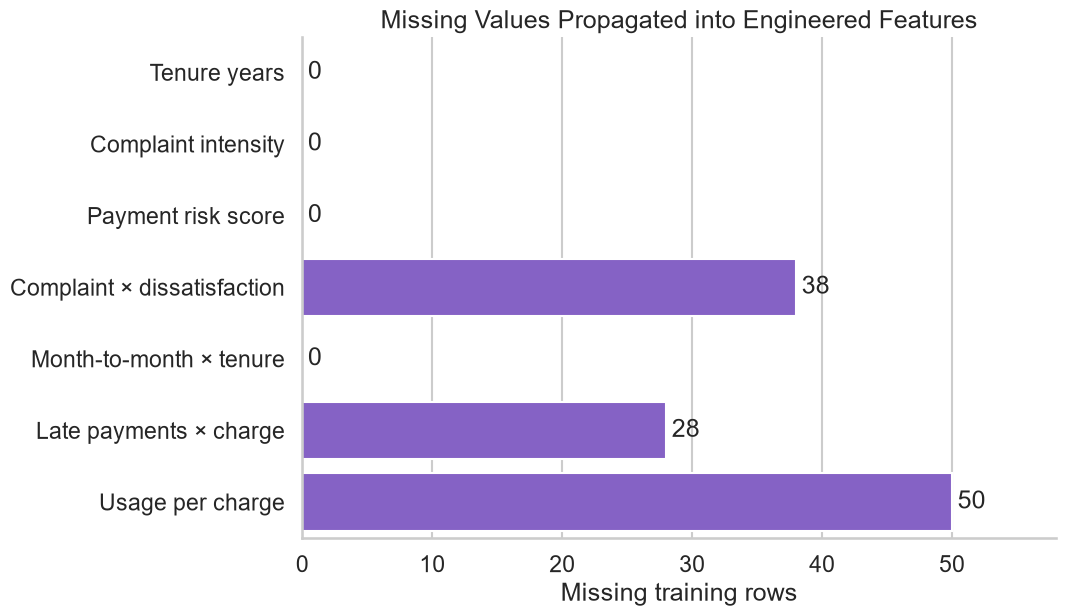

Saved: reports\figures\fe_04_engineered_feature_missingness.png


In [10]:
plot_missing = missing_summary.reset_index(names='feature')
plot_missing['label'] = [
    'Tenure years', 'Complaint intensity', 'Payment risk score',
    'Complaint × dissatisfaction', 'Month-to-month × tenure',
    'Late payments × charge', 'Usage per charge',
]
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.barplot(data=plot_missing, y='label', x='missing_count', color=PURPLE, ax=ax)
for container in ax.containers:
    ax.bar_label(container, padding=4, fmt='%.0f')
ax.set(title='Missing Values Propagated into Engineered Features', xlabel='Missing training rows', ylabel='', xlim=(0, max(55, plot_missing['missing_count'].max() + 8)))
sns.despine(ax=ax)
save_figure(fig, 'fe_04_engineered_feature_missingness.png')

### Interpretation

Three interactions inherit source missingness: 38 rows for complaint-satisfaction, 28 for late-payment charge, and 50 for usage per charge because either usage or monthly charge may be absent. No blanket filling occurs here. A median imputer fitted separately in each future training fold handles these numerical gaps without consulting validation or test rows.

## 12. Integrated leakage-safe preprocessing demonstration

The future architecture is: predictor dataframe → feature engineering → `ColumnTransformer` → fold-fitted imputation/scaling/one-hot encoding → classifier in Phase 5. This demonstration uses an internal 800/160 partition of the approved training data only; it is not a model evaluation.

In [11]:
pipeline_demo_fit = X_train.iloc[:800].copy()
pipeline_demo_unseen = X_train.iloc[800:].copy()
feature_pipeline = build_feature_preprocessing_pipeline()
demo_fit_array = feature_pipeline.fit_transform(pipeline_demo_fit)
demo_unseen_array = feature_pipeline.transform(pipeline_demo_unseen)
preprocessed_names = feature_pipeline.named_steps['preprocessing'].get_feature_names_out()

print(f'Fit rows: {demo_fit_array.shape[0]:,}; transformed columns: {demo_fit_array.shape[1]}')
print(f'Unseen training rows: {demo_unseen_array.shape[0]:,}; transformed columns: {demo_unseen_array.shape[1]}')
print(f'Stable output width: {demo_fit_array.shape[1] == demo_unseen_array.shape[1]}')
print(f'Finite fit output: {np.isfinite(demo_fit_array).all()}')
print(f'Finite unseen output: {np.isfinite(demo_unseen_array).all()}')
print(f'Output feature names: {len(preprocessed_names)}')

Fit rows: 800; transformed columns: 45
Unseen training rows: 160; transformed columns: 45
Stable output width: True
Finite fit output: True
Finite unseen output: True
Output feature names: 45


The feature engineer is stateless. The downstream imputer, scaler, and one-hot encoder learn only from the 800 demonstration fit rows and apply those fitted values to the remaining 160 training rows. In Phase 5 the entire sequence must sit inside the classification pipeline so cross-validation repeats this fit independently in every fold.

## 13. Leakage and integrity verification

In [12]:
expected_figures = [
    'fe_01_engineered_feature_distributions.png',
    'fe_02_source_engineered_relationships.png',
    'fe_03_feature_correlation_heatmap.png',
    'fe_04_engineered_feature_missingness.png',
]
missing_figures = [name for name in expected_figures if not (FIGURE_DIR / name).is_file()]
cleaned_hash_after = hashlib.sha256(CLEANED_PATH.read_bytes()).hexdigest()
split_hash_after = hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest()

assert not missing_figures, f'Missing feature-engineering figures: {missing_figures}'
assert cleaned_hash_before == cleaned_hash_after
assert split_hash_before == split_hash_after
assert split['loaded_existing']
assert len(ENGINEERED_NUMERICAL_FEATURES) == 7
assert engineered_train.shape == (960, 25)
assert not np.isinf(engineered_only.to_numpy(dtype='float64')).any()
assert IDENTIFIER_COLUMN not in engineered_train.columns
assert TARGET_COLUMN not in engineered_train.columns

print(f'Figures verified: {len(expected_figures)}')
print(f'Cleaned dataset unchanged: {cleaned_hash_before == cleaned_hash_after}')
print(f'Saved split unchanged: {split_hash_before == split_hash_after}')
print('Target-derived feature values: 0')
print('Models fitted or predictions generated: 0')

Figures verified: 4
Cleaned dataset unchanged: True
Saved split unchanged: True
Target-derived feature values: 0
Models fitted or predictions generated: 0


## 14. Summary and conclusions

Seven deterministic features were added, increasing the pre-encoding predictor count from 18 to 25 without changing row count or order. The integrated preprocessing output is finite and stable for unseen training rows. No target or identifier enters the transformer, no full-dataset statistics are learned, and no model is trained.

The formulas are technically leakage-safe with respect to target construction, but temporal leakage cannot be ruled out from this dataset alone because source timestamps and event windows are absent. Before Phase 5, the business should confirm that usage, satisfaction, complaint, payment, charge, contract, and tenure values are frozen at the intended prediction date.